# 05. Eksperimen Lanjutan NumPy pada Split Test yang Sama

Notebook ini mereproduksi konfigurasi baseline dan kandidat NumPy dari PR #1 pada 390 baterai yang sama dengan evaluasi final PyTorch tanggal 6 November 2026. Enam checkpoint lokal dipilih dari validation. Hasil NumPy melengkapi laporan final awal dan bersifat deskriptif karena split tersebut sudah pernah dievaluasi.

## 1. Prasyarat

Jalankan `python -m ev_battery all` atau notebook NumPy 00–04 terlebih dahulu. Tahap evaluasi membaca enam `best.npz` dari konfigurasi yang tercatat. Setiap kumpulan identitas berkas memakai direktori lokal sendiri. Evaluator memakai ulang hasil yang lengkap apabila lock dan prediksi cocok.

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from ev_battery.paths import prepare_workspace

ROOT = prepare_workspace(REPO)
from ev_battery.evaluation import run_final_evaluation, file_sha256, canonical_sha256, evaluation_directory
from ev_battery.reporting.final import build_report, read_results

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 5)
print("Root proyek ditemukan. Hasil lanjutan memakai split baterai yang sudah pernah dievaluasi.")

Root proyek ditemukan. Hasil final memakai satu split baterai tetap.


## 2. Konfigurasi NumPy yang dipertahankan

| Model | Resep | Arsitektur | Loss | Optimizer | Parameter |
|---|---|---|---|---|---:|
| Baseline | `baseline_standard` | 67 → [32] sigmoid → 1 linear | MSE | gradient descent, lr 0,1 | 2.209 |
| Kandidat | `baseline_standard` | 67 → [8] sigmoid → 1 linear | MSE | gradient descent, lr 0,1 | 553 |

- Seed training: 42, 123, dan 2026, dengan split tetap.
- Checkpoint: epoch terbaik menurut validation untuk setiap run.
- Batch size 32 dan early stopping dengan patience 15 untuk kedua model.
- Fitur turunan tidak dipakai sesuai keputusan pada studi NumPy asli.
- Tidak ada pemilihan seed dari test, ensemble, atau clipping prediksi.

In [2]:
plan = json.loads((ROOT / "configs/followup.json").read_text(encoding="utf-8"))
planned = pd.DataFrame(
    [
        {"group": group, "seed": int(seed), "recipe": spec["recipe"], "reference_run_id": run_id}
        for group, spec in plan["groups"].items()
        for seed, run_id in spec["reference_run_ids_by_seed"].items()
    ]
)
display(planned)
assert len(planned) == 6 and plan["primary_group_fixed_before_test"] == "candidate"
assert plan["seeds"] == [42, 123, 2026]

,group,seed,recipe,run_id
0,baseline,42,baseline_standard,run_cd4e6f80a183
1,baseline,123,baseline_standard,run_96e0465b8c5f
2,baseline,2026,baseline_standard,run_27c8116694bb
3,candidate,42,baseline_standard,run_0015e8ebf51d
4,candidate,123,baseline_standard,run_17e82e31806b
5,candidate,2026,baseline_standard,run_125d105f67b2


## 3. Lock evaluasi

Sebelum menghitung prediksi pada reproduksi ini, evaluator mencatat hash SHA-256 dari bobot model, pipeline preprocessing, array test, manifest split, konfigurasi, dan kode evaluator ke `evaluation_lock.json`. Setelah inference, semua hash diperiksa ulang untuk memastikan tidak ada yang berubah.

In [3]:
evaluation = run_final_evaluation(root=ROOT)
destination = evaluation_directory(ROOT, evaluation["lock_fingerprint"])
artifacts = build_report(destination)
OUT, evaluation, lock, tables = read_results(destination)
assert evaluation["test_split_previously_evaluated"]
assert evaluation["status"] == "complete"
assert evaluation["test_evaluated"] and not evaluation["training_or_fit_performed"]
assert not evaluation["model_selection_from_test"]
assert canonical_sha256(lock["payload"]) == lock["fingerprint"] == evaluation["lock_fingerprint"]
assert lock["locked_at_utc"] < evaluation["evaluated_at_utc"]
print("Lock UTC:", lock["locked_at_utc"])
print("Evaluasi selesai UTC:", evaluation["evaluated_at_utc"])
print("Fingerprint:", lock["fingerprint"])
print("Primary family sebelum test:", evaluation["primary_group_fixed_before_test"])

LOCKED 6 checkpoints before test predictions: 75b44e65e2f88f74


Lock UTC: 2026-11-07T22:22:25.861474+00:00
Evaluasi selesai UTC: 2026-11-07T22:22:26.919714+00:00
Fingerprint: 75b44e65e2f88f74f3c276f1e7e4fbff79bbcdc2e67ff5a6a473b979da5e90e4
Primary family sebelum test: candidate


In [4]:
identity = pd.DataFrame(lock["payload"]["files_sha256"].items(), columns=["berkas_dikunci", "sha256"])
for relative, expected in lock["payload"]["files_sha256"].items():
    assert file_sha256(ROOT / relative) == expected, relative
assert file_sha256(REPO / "src/ev_battery/evaluation.py") == lock["payload"]["source_sha256"]
display(identity)
print("Seluruh identitas berkas terkunci masih cocok.")

,berkas_dikunci,sha256
0,configs/feature_contract.json,1cffec850bb7b84a5837d635ec4055d6d6fd1921dd54e7...
1,configs/final_evaluation.json,0c751aab276a6ebe6d2289cc3f5bf58f7a6f62dc9bf83a...
2,configs/mlp_study.json,d23cfac31919feefac6dc561a1720aca361e3fb743bd26...
3,configs/preprocessing.json,d2d8ec51a4242f10fe58d9cb24f80b4352bf8c3282ae88...
4,data/processed/baseline_standard/test.npz,3d4b318c2eab9f1517316165013dcb2f31a1aba2be20a5...
5,data/splits/battery_split.csv,9529f65692528d6f9ed63773880a84c75d0b28d0a8b780...
6,models/mlp/run_0015e8ebf51d/best.npz,fa4c61d6739794e69847be209e222cea2567c2b8c29d36...
7,models/mlp/run_125d105f67b2/best.npz,8bac421fa2912dfd1c10176dbbef2c5bef1d693dfcf4dd...
8,models/mlp/run_17e82e31806b/best.npz,cbce957f3b90a6c50e1bd54304db5ca4ede271866e546b...
9,models/mlp/run_27c8116694bb/best.npz,fe6896765820041cf640971351d0eeb8b7ed43c44e413b...


Seluruh identitas berkas terkunci masih cocok.


## 4. Populasi test

Test berisi **7.572 observasi dari 390 baterai** yang terpisah dari 1.820 baterai train dan 390 baterai validation. Karena observasi dari baterai yang sama saling berkaitan, error dilaporkan dua cara: rata-rata per observasi dan rata-rata per baterai.

In [5]:
manifest = pd.read_csv(ROOT / "data/splits/battery_split.csv")
split_ids = {name: set(sub.battery_id) for name, sub in manifest.groupby("split")}
assert not (split_ids["train"] & split_ids["validation"])
assert not (split_ids["train"] & split_ids["test"])
assert not (split_ids["validation"] & split_ids["test"])
assert len(split_ids["test"]) == 390
metrics = tables["metrics_by_seed"]
assert metrics.test_rows.eq(7572).all() and metrics.test_batteries.eq(390).all()
assert metrics.groupby("group").seed.apply(lambda s: set(s) == {42, 123, 2026}).all()
display(manifest.groupby("split").size().rename("baterai").to_frame())

,baterai
split,
test,390
train,1820
validation,390


## 5. Metrik

Dengan error $e_i=\hat y_i-y_i$:

- $MAE=\frac{1}{n}\sum_i |e_i|$
- $RMSE=\sqrt{\frac{1}{n}\sum_i e_i^2}$
- $R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}$
- Bias adalah rerata $e_i$. Nilai positif berarti SOH diprediksi terlalu tinggi.

MAE 0,96 berarti rata-rata selisih absolut **0,96 poin persentase SOH**, bukan "akurasi 99,04%". Mean ± SD dihitung dari metrik ketiga seed (sample SD, `ddof=1`), sehingga menggambarkan variasi training, bukan confidence interval.

,test_mae_mean_pp,test_mae_sd_pp,test_rmse_mean_pp,test_rmse_sd_pp,test_r2_mean,test_r2_sd,test_battery_mae_mean_pp,parameters
group,,,,,,,,
baseline,0.96018,0.00641,1.40619,0.00799,0.95785,0.00048,0.96278,2209
candidate,0.97268,0.00325,1.43615,0.00465,0.95603,0.00028,0.97442,553


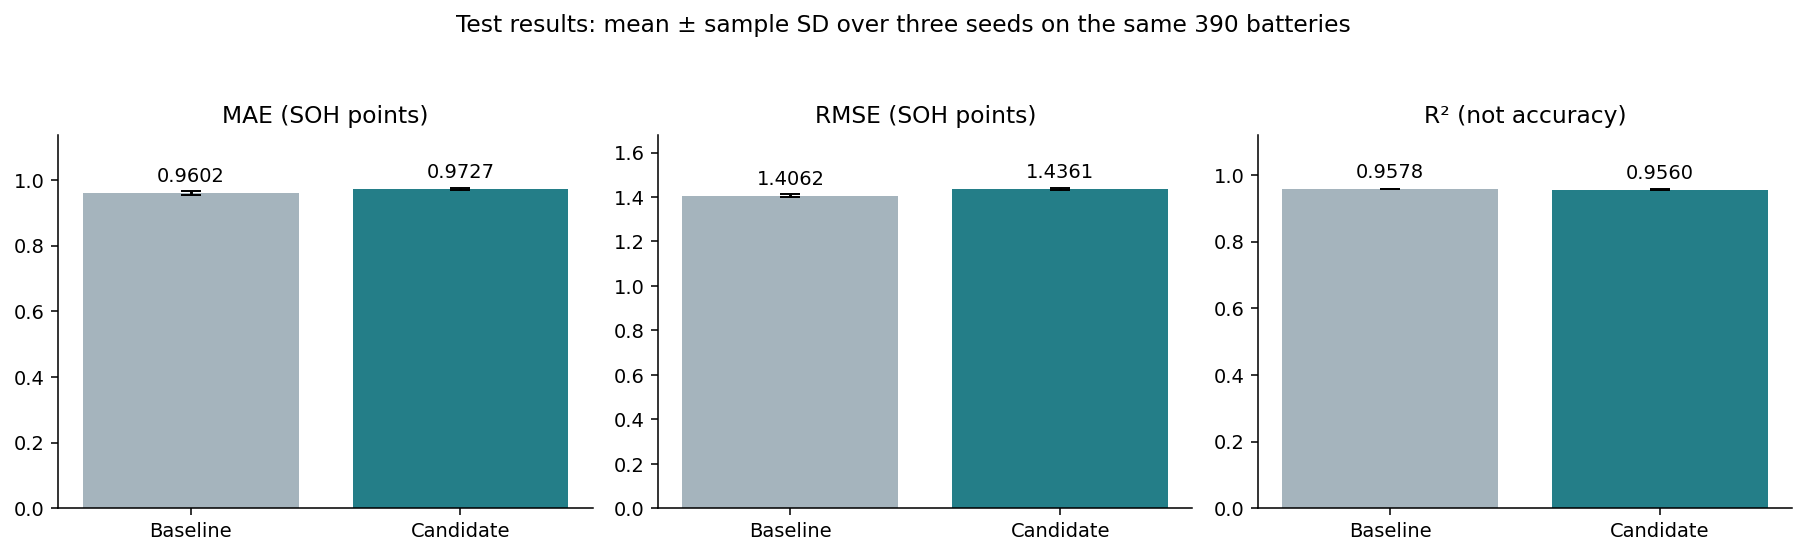

Selisih MAE baseline − kandidat: -0.01250 poin SOH (-1.30% relatif).


In [6]:
summary = tables["metrics_summary"].set_index("group")
columns = [
    "test_mae_mean_pp",
    "test_mae_sd_pp",
    "test_rmse_mean_pp",
    "test_rmse_sd_pp",
    "test_r2_mean",
    "test_r2_sd",
    "test_battery_mae_mean_pp",
    "parameters",
]
display(summary[columns])
display(Image(filename=str(OUT / "01_test_metrics.png")))
gain = summary.loc["baseline", "test_mae_mean_pp"] - summary.loc["candidate", "test_mae_mean_pp"]
print(
    f"Selisih MAE baseline − kandidat: {gain:.5f} poin SOH ({100 * gain / summary.loc['baseline', 'test_mae_mean_pp']:.2f}% relatif)."
)

**Interpretasi arsip PR #1:** baseline memiliki MAE sekitar 0,0125 poin lebih rendah pada split ini. Kandidat memiliki 553 parameter dibanding 2.209 pada baseline. Gunakan tabel di atas untuk angka reproduksi lokal.

## 6. Hasil per seed

Semua seed ditampilkan. Kolom epoch berasal dari validation, bukan dari test.

In [7]:
display(
    metrics[
        [
            "group",
            "seed",
            "run_id",
            "best_epoch_from_validation",
            "train_mae_pp",
            "validation_mae_pp",
            "test_mae_pp",
            "test_rmse_pp",
            "test_r2",
            "test_outside_0_100_pct",
        ]
    ]
)
for row in summary.itertuples():
    values = metrics.loc[metrics.group.eq(row.Index), "test_mae_pp"]
    np.testing.assert_allclose(
        [values.mean(), values.std(ddof=1)], [row.test_mae_mean_pp, row.test_mae_sd_pp], rtol=1e-10
    )
print("Rerata/SD MAE cocok dengan seluruh seed, tanpa memilih satu seed terbaik.")

,group,seed,run_id,best_epoch_from_validation,train_mae_pp,validation_mae_pp,test_mae_pp,test_rmse_pp,test_r2,test_outside_0_100_pct
0,baseline,42,run_cd4e6f80a183,62,0.94726,1.00682,0.95973,1.40074,0.95817,1.01690
1,baseline,123,run_96e0465b8c5f,41,0.96014,0.99881,0.95400,1.40248,0.95807,0.55468
2,baseline,2026,run_27c8116694bb,49,0.94523,0.99427,0.96680,1.41536,0.95730,0.33016
3,candidate,42,run_0015e8ebf51d,96,0.96289,0.99428,0.97244,1.44020,0.95578,0.21130
4,candidate,123,run_17e82e31806b,56,0.97488,1.00942,0.96956,1.43107,0.95634,1.61120
5,candidate,2026,run_125d105f67b2,58,0.97048,0.99594,0.97604,1.43717,0.95597,0.40940


Rerata/SD MAE cocok dengan seluruh seed, tanpa memilih satu seed terbaik.


## 7. Train, validation, dan test

Grafik membandingkan error checkpoint yang sama pada ketiga split. Selisih mencerminkan hasil pada kelompok baterai dari simulator yang sama.

,group,train_mae_mean_pp,validation_mae_mean_pp,test_mae_mean_pp,test_minus_validation_pp
0,baseline,0.95088,0.99997,0.96018,-0.03979
1,candidate,0.96941,0.99988,0.97268,-0.02720


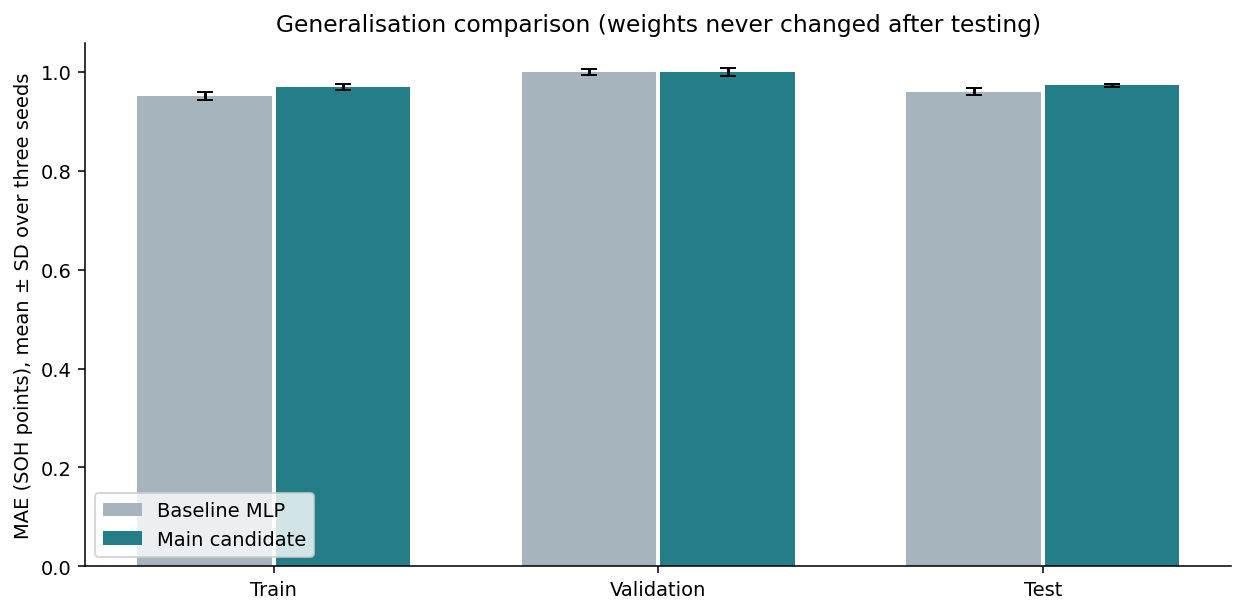

In [8]:
display(tables["validation_test_comparison"])
display(Image(filename=str(OUT / "02_train_validation_test.png")))

## 8. Aktual vs prediksi

Scatter plot memakai **seed 42**, yaitu seed pertama dalam rencana, bukan seed dengan hasil test terbaik. Garis diagonal menunjukkan prediksi sempurna.

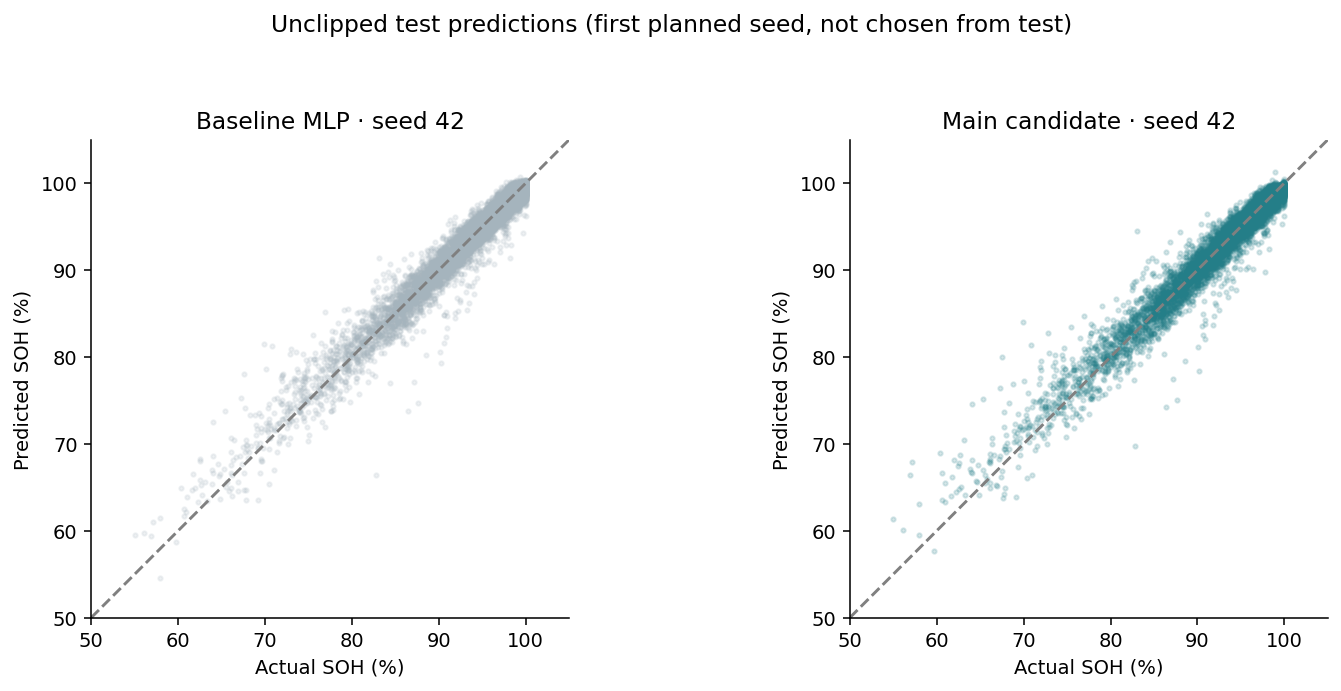

Visual menggunakan seed pertama yang sudah dikunci, bukan seed test terbaik.


In [9]:
display(Image(filename=str(OUT / "03_actual_predictions.png")))
representative_seed = plan["seeds"][0]
assert representative_seed == 42
predictions = {
    group: pd.read_csv(OUT / "predictions" / f"{group}_seed_{representative_seed}.csv")
    for group in plan["groups"]
}
for group, frame in predictions.items():
    assert len(frame) == 7572 and set(frame.battery_id) == split_ids["test"]
print("Visual menggunakan seed pertama yang sudah dikunci, bukan seed test terbaik.")

## 9. Error per rentang SOH

Rentang SOH ditetapkan sebelum testing, dan distribusi test tidak diubah.

**Temuan penting:** kedua model paling lemah pada **SOH di bawah 70%**. MAE baseline sekitar **2,78** dan kandidat **3,05** poin, kira-kira tiga kali error rata-rata. Rentang ini hanya berisi 88 observasi dari 23 baterai. Bias kandidat sekitar **+2,39 poin**, artinya baterai yang sangat terdegradasi cenderung diprediksi lebih sehat dari kondisi sebenarnya. Kandidat hanya sedikit lebih baik dari baseline pada SOH ≥95%.

,group,soh_band,rows,batteries,mae_mean_pp,mae_sd_pp,rmse_mean_pp,bias_mean_pp
0,baseline,<70,88,23,2.77533,0.05902,3.64920,1.91158
1,baseline,70–<80,362,83,1.96402,0.05101,2.59212,0.94390
2,baseline,80–<90,1442,226,1.30142,0.02610,1.80092,0.16923
3,baseline,90–<95,1888,324,0.96419,0.00521,1.37460,0.05032
4,baseline,>=95,3792,385,0.69046,0.00686,0.90730,-0.16422
5,candidate,<70,88,23,3.05337,0.33421,4.10635,2.38920
6,candidate,70–<80,362,83,2.06491,0.02880,2.70881,1.20826
7,candidate,80–<90,1442,226,1.31848,0.01148,1.81810,0.28224
8,candidate,90–<95,1888,324,0.98387,0.01453,1.38786,0.09385
9,candidate,>=95,3792,385,0.68305,0.01067,0.89912,-0.13281


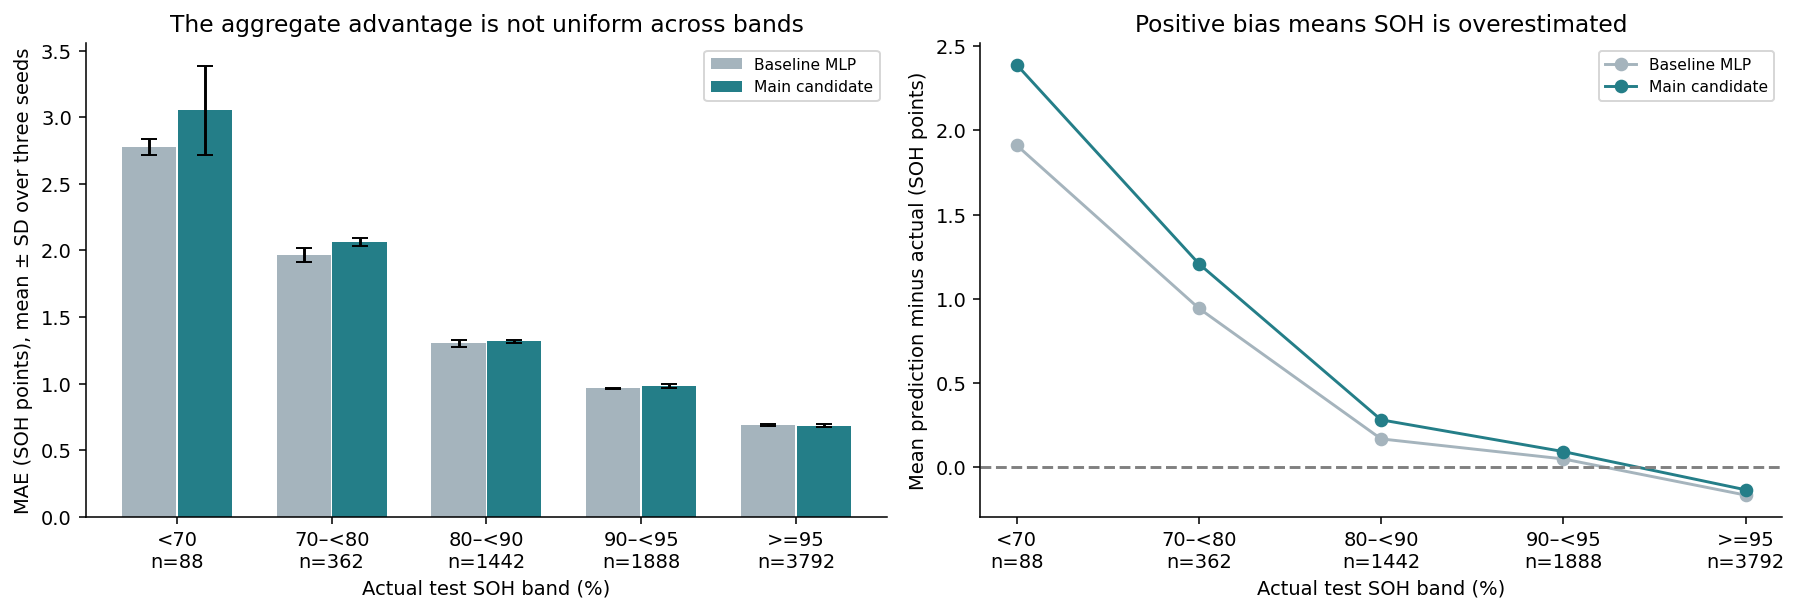

In [10]:
bands = tables["test_band_summary"]
display(bands)
display(Image(filename=str(OUT / "04_test_soh_bands.png")))
for group, frame in bands.groupby("group"):
    assert frame.rows.sum() == 7572
low = bands.loc[bands.soh_band.eq("<70")].set_index("group")
assert low.loc["candidate", "mae_mean_pp"] > low.loc["baseline", "mae_mean_pp"]
assert low.loc["candidate", "rows"] == 88 and low.loc["candidate", "batteries"] == 23

Analisis rentang SOH menggambarkan kelemahan model pada split ini. Evaluasi baru yang independen memerlukan kelompok baterai lain.

## 10. Error per baterai

MAE per observasi memberi bobot lebih besar pada baterai yang memiliki banyak observasi. Sebagai pelengkap, MAE dihitung per baterai lalu dirata-ratakan untuk 390 baterai. Kandidat lebih akurat pada 182 dari 390 baterai, jadi kedua model hampir seimbang di tingkat baterai. Sepuluh baterai dengan error terbesar ditampilkan untuk diagnosis.

,test_mae_mean_pp,test_battery_mae_mean_pp,test_battery_mae_sd_pp
group,,,
baseline,0.96018,0.96278,0.00650
candidate,0.97268,0.97442,0.00429


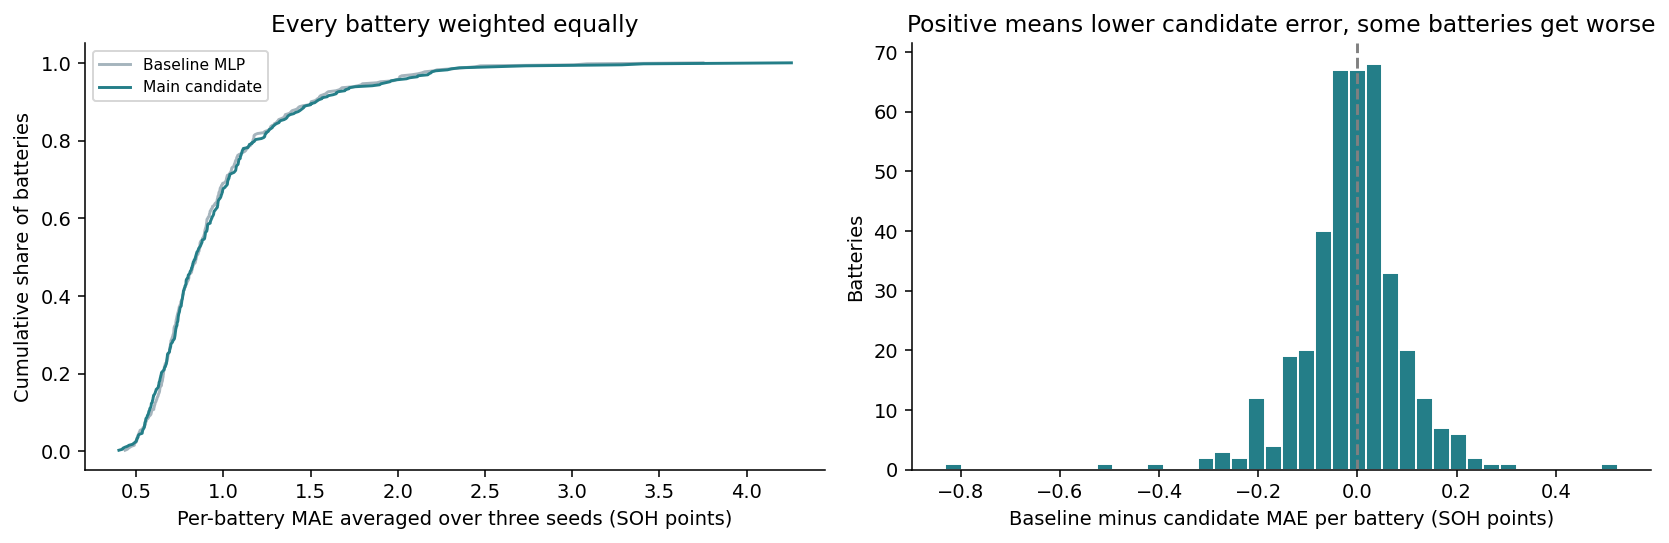

Baterai dengan MAE kandidat lebih rendah: 182 /390


,group,battery_id,rows,mean_actual_soh,mae_mean_pp,mae_sd_pp,rmse_mean_pp,bias_mean_pp
0,candidate,BATT_00668,21,82.61143,4.25742,0.16137,5.46338,4.08086
1,candidate,BATT_00438,20,79.00800,3.40969,0.09089,4.32580,3.14142
2,candidate,BATT_02542,18,82.20667,3.28580,0.08603,3.69991,-2.01104
3,candidate,BATT_02298,22,73.88773,2.73278,0.80431,3.52739,2.32897
4,candidate,BATT_01952,17,78.47765,2.54612,0.04755,2.75290,2.54612
5,candidate,BATT_02345,21,87.20238,2.35342,0.20302,2.63732,-1.97480
6,candidate,BATT_01357,20,87.05500,2.30826,0.16076,2.96279,2.20617
7,candidate,BATT_00526,18,94.16500,2.28581,0.10527,3.64134,-1.69016
8,candidate,BATT_00988,18,87.06500,2.21796,0.20264,2.83937,2.11245
9,candidate,BATT_00643,7,87.17429,2.19533,0.11091,2.60781,2.17546


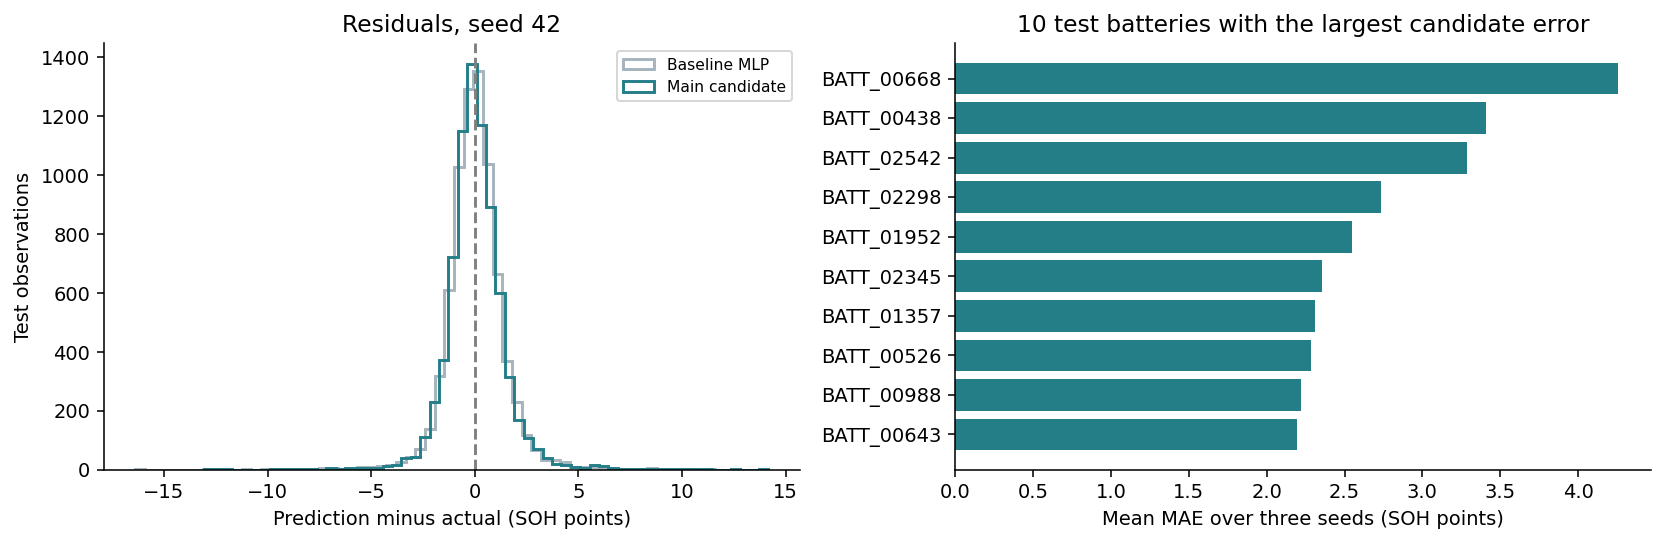

In [11]:
display(summary[["test_mae_mean_pp", "test_battery_mae_mean_pp", "test_battery_mae_sd_pp"]])
display(Image(filename=str(OUT / "05_battery_errors.png")))
paired = pd.read_csv(OUT / "paired_battery_mae.csv")
assert len(paired) == 390
print(
    "Baterai dengan MAE kandidat lebih rendah:",
    int(paired.baseline_minus_candidate_mae_pp.gt(0).sum()),
    "/390",
)
display(pd.read_csv(OUT / "largest_candidate_battery_errors.csv"))
display(Image(filename=str(OUT / "06_residuals_and_largest_errors.png")))

## 11. Prediksi di luar rentang dan pembanding konstan

Output linear bisa menghasilkan nilai di bawah 0 atau di atas 100. Prediksi tidak dipotong (clipping), dan proporsinya dilaporkan sebagai keterbatasan.

Median dan rerata SOH train dipakai sebagai pembanding konstan untuk memastikan MLP memberi manfaat nyata dibanding menebak nilai tengah.

In [12]:
display(summary[["test_bias_mean_pp", "test_outside_0_100_mean_pct"]])
display(tables["constant_references"])

,test_bias_mean_pp,test_outside_0_100_mean_pct
group,,
baseline,0.02987,0.63391
candidate,0.09617,0.74397


,reference,constant_from_train,mae,rmse,r2,bias_pp,outside_0_100_pct,battery_mean_mae
0,train_median,95.23000,4.93024,7.22279,-1.12111e-01,2.29327,0.0,4.93412
1,train_mean,92.91875,5.19750,6.84908,-6.89725e-06,-0.01799,0.0,5.21201


## 12. Verifikasi independen

Metrik dihitung ulang langsung dari file prediksi menggunakan NumPy, terpisah dari fungsi evaluator, lalu dicocokkan dengan tabel hasil.

In [13]:
checks = []
for row in metrics.itertuples():
    frame = pd.read_csv(OUT / "predictions" / f"{row.group}_seed_{row.seed}.csv")
    actual = frame.actual_soh.to_numpy()
    error = frame.predicted_soh.to_numpy() - actual
    computed = [
        np.abs(error).mean(),
        np.sqrt(np.square(error).mean()),
        1 - np.square(error).sum() / np.square(actual - actual.mean()).sum(),
        error.mean(),
        frame.assign(ae=np.abs(error)).groupby("battery_id").ae.mean().mean(),
    ]
    recorded = [
        row.test_mae_pp,
        row.test_rmse_pp,
        row.test_r2,
        row.test_bias_pp,
        row.test_battery_mean_mae_pp,
    ]
    np.testing.assert_allclose(computed, recorded, rtol=1e-10, atol=1e-10)
    assert len(frame) == 7572 and frame.observation_id.is_unique
    assert set(frame.battery_id) == split_ids["test"]
    checks.append({"group": row.group, "seed": row.seed, "independent_metrics": "cocok"})
display(pd.DataFrame(checks))

,group,seed,independent_metrics
0,baseline,42,cocok
1,baseline,123,cocok
2,baseline,2026,cocok
3,candidate,42,cocok
4,candidate,123,cocok
5,candidate,2026,cocok


## 13. Unit test

Seluruh unit test dijalankan ulang, termasuk pemeriksaan bahwa lock menolak perubahan, seed tidak bisa dipilih sepihak, dan inference tidak memanggil training.

In [14]:
verification = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=REPO,
    capture_output=True,
    text=True,
)
if verification.returncode:
    print(verification.stdout)
    print(verification.stderr)
assert verification.returncode == 0, "Periksa kegagalan test sebelum membagikan hasil."
print("\n".join(verification.stderr.strip().splitlines()[-4:]))
for relative, expected in lock["payload"]["files_sha256"].items():
    assert file_sha256(ROOT / relative) == expected, relative
print("Artefak final tetap identik setelah semua pemeriksaan.")

----------------------------------------------------------------------
Ran 35 tests in 0.734s

OK
Artefak final tetap identik setelah semua pemeriksaan.


## 14. Kesimpulan

Pada snapshot PR #1, baseline NumPy mencapai MAE 0,96018 ± 0,00641 poin SOH dan kandidat 0,97268 ± 0,00325. Kandidat menggunakan sekitar seperempat jumlah parameter baseline. Error terbesar tetap terdapat pada SOH rendah. Temuan ini berlaku pada estimasi SOH sintetis untuk split yang sama. Laporan evaluasi final awal tersimpan di `results/final_evaluation/`.

## 15. Artefak dan reproduksi

```bash
python -m ev_battery all
python scripts/run_notebook.py notebooks/numpy/05_final_evaluation.ipynb
```

Hasil lokal, termasuk metrik, grafik dan lock, berada di `data/processed/numpy_workspace/results/numpy_followup/<fingerprint>/`. Snapshot awal PR #1 tersedia di `results/numpy/final_evaluation/`.